# Student Dropout & Academic Success - Classification Project
## Notebook 3: Final Testing -> Deployment Preparation -> Monitoring

**Covers ML process steps 8 (Model Testing and Deployment) and 10 (Monitoring and Maintenance).**

Up to now the **test set was locked away**. In this notebook we open it **once** to measure how the chosen models perform on students they have never seen. This is the number we report as our real performance.

> **Why is the test set so special?** Every decision in Notebooks 1-2 (which model, which settings, which threshold) was made by looking at validation data. Those choices make validation scores slightly *optimistic*. The test set was never used for any decision, so its score is an honest estimate of real-world performance.

In [1]:
import os, json, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, ConfusionMatrixDisplay, classification_report)
from sklearn.utils.class_weight import compute_sample_weight

from inference import add_engineered, predict_with_threshold, predict_students, CLASSES, ENGINEERED
import monitor

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50, "display.width", 200)

SEED = 42
FIG, MODELS = Path("figures"), Path("models")
PALETTE = {"Dropout": "#d1495b", "Enrolled": "#edae49", "Graduate": "#00798c"}
TARGET_F1, TARGET_RECALL = 0.70, 0.75

def save(name):
    plt.tight_layout(); plt.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")

def lean(pipe):
    """Run the model on one thread. On a small dataset many threads wait for each other (we measured 17-40 s per fit with
    12 threads against 0.2-0.5 s with 1 thread in the second project), and one thread is also right for single web requests."""
    if "n_jobs" in pipe.named_steps["model"].get_params():
        pipe.set_params(model__n_jobs=1)
    return pipe

S = Path("data/splits")
train, val, test = (pd.read_csv(S / f"{n}.csv") for n in ["train", "val", "test"])
cfg = json.load(open(MODELS / "config.json"))
fitted = {s: lean(joblib.load(MODELS / f"{s}_fitted_on_train.joblib")) for s in cfg}
split = {n: (d.drop(columns="target"), d["target"].values) for n, d in [("train", train), ("val", val), ("test", test)]}
for s in cfg:
    print(f"{s:>5}: {cfg[s]['model']}, decision threshold t = {cfg[s]['threshold']}")
print("test students:", len(test))

 full: XGBoost (Optuna), decision threshold t = 0.325
early: Random Forest (Random), decision threshold t = 0.325
test students: 664


---
# Step 8.1 - Final evaluation on the test set

We evaluate the **exact pipelines validated in Notebook 2** (trained on the training set only), with two decision rules:
* **default rule** - pick the most probable class;
* **threshold rule** - flag "Dropout" whenever P(Dropout) >= t (more sensitive to dropouts).

Alongside each score we give a **95% confidence interval** computed by **bootstrapping**: we re-draw the 664 test students *with replacement* 2,000 times and recompute the score each time. The spread tells us how much a score would wobble just from which students happened to land in the test set. *A wide interval means "do not trust the third decimal place".*

In [2]:
rng = np.random.default_rng(SEED)
y_test = split["test"][1]

def predict_rule(scen, X, rule):
    proba = fitted[scen].predict_proba(X[cfg[scen]["features"]])
    pred = proba.argmax(axis=1) if rule == "default" else predict_with_threshold(proba, cfg[scen]["threshold"])
    return proba, pred

def metrics(y, pred, proba):
    return {"accuracy": accuracy_score(y, pred),
            "macro_f1": f1_score(y, pred, average="macro"),
            "dropout_recall": recall_score(y, pred, labels=[0], average=None)[0],
            "dropout_precision": precision_score(y, pred, labels=[0], average=None, zero_division=0)[0],
            "roc_auc": roc_auc_score(y, proba, multi_class="ovr", average="macro")}

def bootstrap_ci(y, pred, n=2000):
    idx = rng.integers(0, len(y), size=(n, len(y)))
    f1s = [f1_score(y[i], pred[i], average="macro") for i in idx]
    rec = [recall_score(y[i], pred[i], labels=[0], average=None)[0] for i in idx]
    return np.percentile(f1s, [2.5, 97.5]), np.percentile(rec, [2.5, 97.5])

rows = []
for scen in cfg:
    for rule in ["default", "threshold"]:
        pv, prv = predict_rule(scen, split["val"][0], rule)
        pt, prt = predict_rule(scen, split["test"][0], rule)
        mv, mt = metrics(split["val"][1], prv, pv), metrics(y_test, prt, pt)
        f1_ci, rec_ci = bootstrap_ci(y_test, prt)
        rows.append({"scenario": scen, "model": cfg[scen]["model"].split(" (")[0], "rule": rule,
                     "val_macro_f1": mv["macro_f1"], "TEST_macro_f1": mt["macro_f1"],
                     "f1_95%CI": f"{f1_ci[0]:.3f}-{f1_ci[1]:.3f}",
                     "val_dropout_recall": mv["dropout_recall"], "TEST_dropout_recall": mt["dropout_recall"],
                     "recall_95%CI": f"{rec_ci[0]:.3f}-{rec_ci[1]:.3f}",
                     "TEST_dropout_precision": mt["dropout_precision"],
                     "TEST_accuracy": mt["accuracy"], "TEST_roc_auc": mt["roc_auc"]})
final = pd.DataFrame(rows)
final["meets F1 target"] = final["TEST_macro_f1"] >= TARGET_F1
final["meets recall target"] = final["TEST_dropout_recall"] >= TARGET_RECALL
final.round(3)

,scenario,model,rule,val_macro_f1,TEST_macro_f1,f1_95%CI,val_dropout_recall,TEST_dropout_recall,recall_95%CI,TEST_dropout_precision,TEST_accuracy,TEST_roc_auc,meets F1 target,meets recall target
0,full,XGBoost,default,0.702,0.757,0.722-0.790,0.704,0.762,0.700-0.819,0.881,0.791,0.912,True,True
1,full,XGBoost,threshold,0.691,0.741,0.705-0.776,0.751,0.832,0.784-0.882,0.809,0.788,0.912,True,True
2,early,Random Forest,default,0.679,0.696,0.659-0.732,0.690,0.771,0.714-0.828,0.801,0.758,0.886,False,True
3,early,Random Forest,threshold,0.642,0.664,0.627-0.702,0.770,0.860,0.815-0.906,0.730,0.752,0.886,False,True


### Reference points on the same test set
The "always predict Graduate" baseline - to remind ourselves what "no learning" scores:

In [3]:
base_pred = np.full(len(y_test), 2)
print("Baseline  accuracy: %.3f | macro-F1: %.3f | Dropout recall: %.3f" % (
    accuracy_score(y_test, base_pred), f1_score(y_test, base_pred, average="macro"),
    recall_score(y_test, base_pred, labels=[0], average=None, zero_division=0)[0]))

Baseline  accuracy: 0.498 | macro-F1: 0.222 | Dropout recall: 0.000


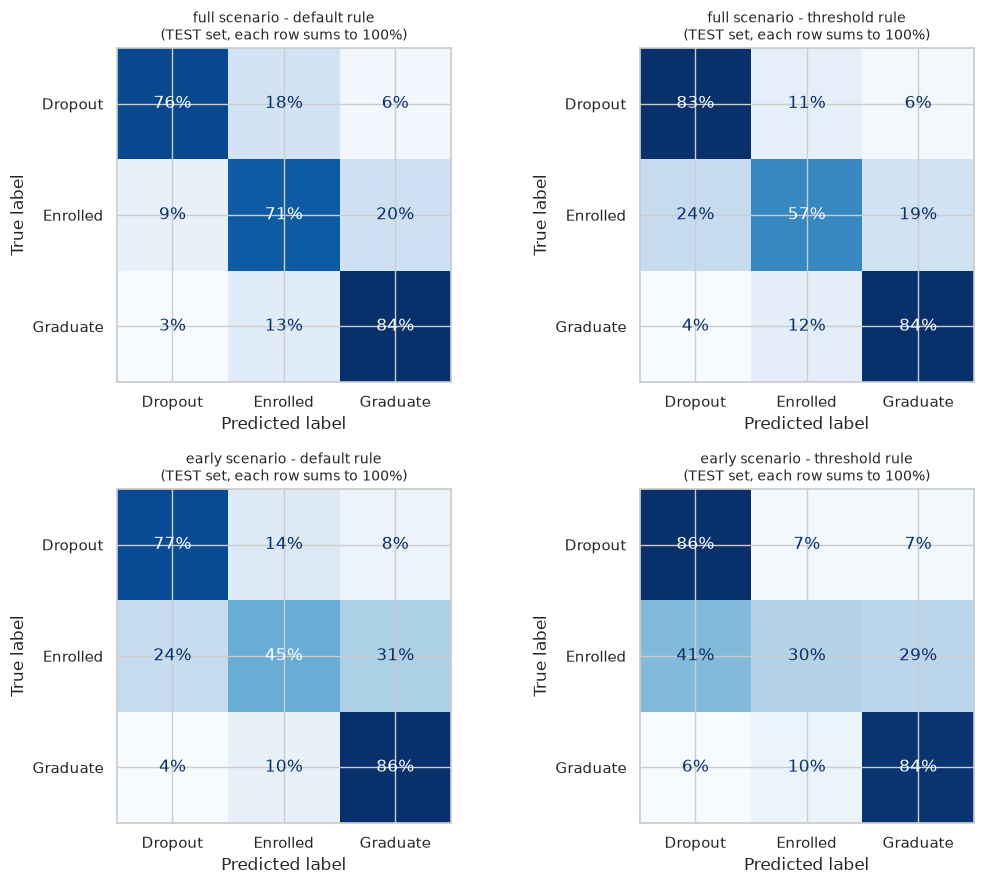

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for r, scen in enumerate(cfg):
    for c, rule in enumerate(["default", "threshold"]):
        _, pred = predict_rule(scen, split["test"][0], rule)
        ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=CLASSES, normalize="true",
                                                values_format=".0%", cmap="Blues", ax=axes[r, c], colorbar=False)
        axes[r, c].set_title(f"{scen} scenario - {rule} rule\n(TEST set, each row sums to 100%)", fontsize=10)
save("17_test_confusion_matrices")
plt.show()

In [5]:
for scen in cfg:
    for rule in ["default", "threshold"]:
        _, pred = predict_rule(scen, split["test"][0], rule)
        print(f"\n===== TEST | {scen} scenario | {cfg[scen]['model']} | {rule} rule =====")
        print(classification_report(y_test, pred, target_names=CLASSES, digits=3))


===== TEST | full scenario | XGBoost (Optuna) | default rule =====
              precision    recall  f1-score   support

     Dropout      0.881     0.762     0.817       214
    Enrolled      0.509     0.706     0.592       119
    Graduate      0.885     0.840     0.862       331

    accuracy                          0.791       664
   macro avg      0.759     0.769     0.757       664
weighted avg      0.817     0.791     0.799       664


===== TEST | full scenario | XGBoost (Optuna) | threshold rule =====
              precision    recall  f1-score   support

     Dropout      0.809     0.832     0.820       214
    Enrolled      0.515     0.571     0.542       119
    Graduate      0.888     0.837     0.862       331

    accuracy                          0.788       664
   macro avg      0.737     0.747     0.741       664
weighted avg      0.796     0.788     0.791       664


===== TEST | early scenario | Random Forest (Random) | default rule =====
              precision  

### Validation vs. test: did the model generalise?
**Generalisation** = performing well on *new* data. If the test score is similar to the validation score, the model generalises. A big drop would mean we over-fitted to the validation set during model selection.

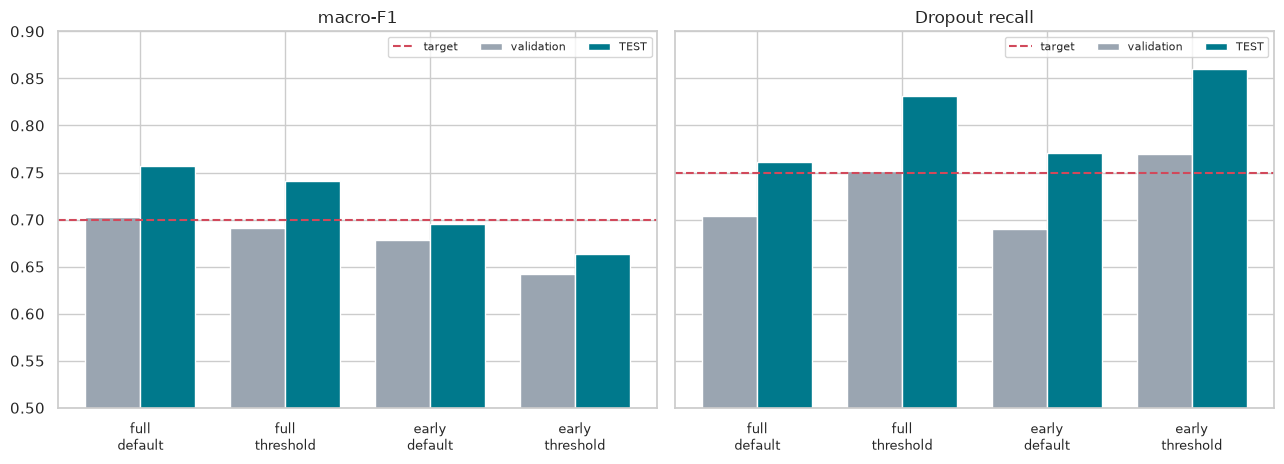

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, metric, title in zip(axes, ["macro_f1", "dropout_recall"], ["macro-F1", "Dropout recall"]):
    labels = [f"{r.scenario}\n{r.rule}" for r in final.itertuples()]
    x = np.arange(len(final)); w = 0.38
    ax.bar(x - w/2, final[f"val_{metric}"], w, label="validation", color="#9aa5b1")
    ax.bar(x + w/2, final[f"TEST_{metric}"], w, label="TEST", color="#00798c")
    ax.axhline(TARGET_F1 if metric == "macro_f1" else TARGET_RECALL, color="#d1495b", ls="--", label="target")
    ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=9); ax.set_title(title); ax.set_ylim(0.5, 0.9)
    ax.legend(loc="upper right", ncol=3, fontsize=8)
save("18_validation_vs_test")
plt.show()

### What the test results tell us
**Full model (XGBoost).** Default rule: macro-F1 **0.757** (95% CI 0.722-0.790) and Dropout recall **0.762** (0.700-0.819) - *both* success targets are met. With the lowered threshold, Dropout recall rises to 0.832 and macro-F1 is 0.741 - both targets still met.

**Early-warning model (Random Forest).** Default rule: macro-F1 **0.696** (0.659-0.732) - essentially *at* the 0.70 target (the interval contains it) - and Dropout recall 0.771 (target met). With the lowered threshold, recall climbs to 0.860 but macro-F1 falls to 0.664 and Dropout precision to 0.73. The price is paid by the *Enrolled* group: its recall drops from 0.45 to 0.30, because borderline students are pushed into the Dropout label.

**Test scores are higher than validation scores** (macro-F1 +0.02 to +0.06, Dropout recall +0.06 to +0.09). Please do not read this as "the model got better". The test set is simply a *different random sample of 664 students*, and the confidence intervals (about +/-0.035) show that gaps of this size can happen by chance. What *is* reassuring is the direction: the test score is **not lower** than validation, so we find no sign that model selection over-fitted the validation set. A cautious way to report performance is to quote the **test result with its interval** and mention that validation scores were somewhat lower.

**Early warning costs a bit more here than in validation:** test macro-F1 0.757 (full) vs 0.696 (early), a gap of about 0.06, compared with 0.02-0.04 in Notebook 2. Because of the interval widths, a fair summary is *"roughly 0.03 to 0.06"*.

**The Enrolled class is still the weak spot** (F1 0.59 for the full model, 0.45 for the early model).

**Which rule is deployed?** The app uses the **threshold rule** (t = 0.325), because for an early-warning tool missing a student who will drop out is the costly error: it flags 83% (full) and 86% (early) of real dropouts on the test set. The cost is more false alarms and weaker "Enrolled" predictions. If advisors have limited capacity, a higher threshold (closer to the default rule) is a legitimate choice - the trade-off curves are in Notebook 2 (Figure 16).

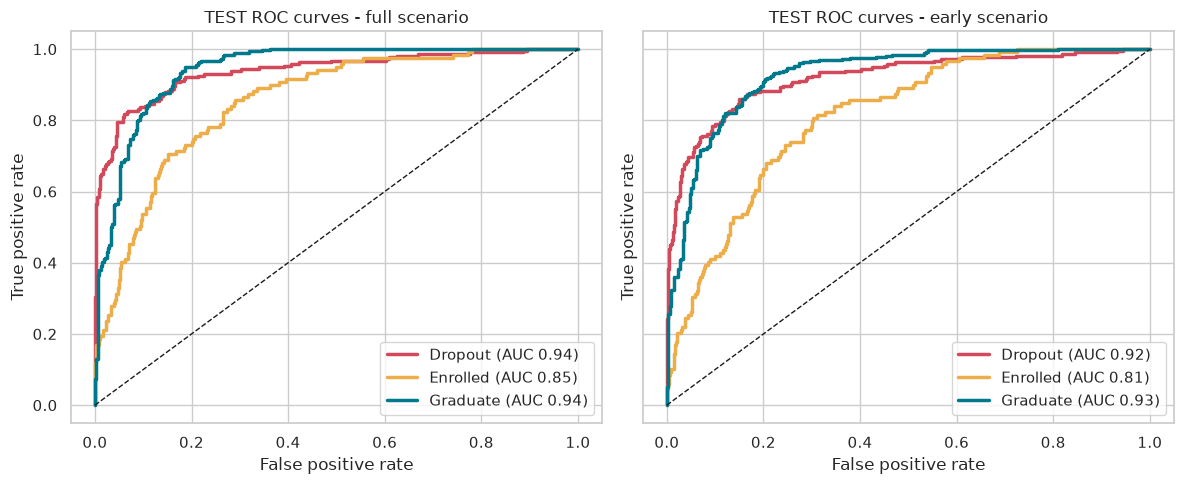

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, scen in zip(axes, cfg):
    proba, _ = predict_rule(scen, split["test"][0], "default")
    for i, c in enumerate(CLASSES):
        yy = (y_test == i).astype(int)
        fpr, tpr, _ = roc_curve(yy, proba[:, i])
        ax.plot(fpr, tpr, color=PALETTE[c], lw=2.5, label=f"{c} (AUC {roc_auc_score(yy, proba[:, i]):.2f})")
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.set_title(f"TEST ROC curves - {scen} scenario"); ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
    ax.legend(loc="lower right")
save("19_test_roc_curves")
plt.show()

---
# Step 8.2 - Preparing the model for deployment

### Retrain on train + validation
Now that evaluation is finished, we no longer need to keep validation data aside. For the model that will *actually be used*, we retrain the **same pipeline with the same settings** on **train + validation together** (85% of all students) - more examples usually means a slightly better model. We first run a **sanity check**: its predictions on the test students should agree closely with the train-only model's predictions. This deployed model has never seen the test students either, so after building it we can also measure it on the test set as one more check. We keep the train-only numbers above as our headline results, so that nothing is chosen after looking at the test set.

In [8]:
X_tv = pd.concat([split["train"][0], split["val"][0]], ignore_index=True)
y_tv = np.concatenate([split["train"][1], split["val"][1]])

bundle = {}
for scen in cfg:
    pipe = lean(joblib.load(MODELS / f"{scen}_unfitted.joblib"))
    cols = cfg[scen]["features"]
    if cfg[scen]["balanced_sample_weights"]:
        pipe.fit(X_tv[cols], y_tv, model__sample_weight=compute_sample_weight("balanced", y_tv))
    else:
        pipe.fit(X_tv[cols], y_tv)

    # sanity check only: do the old and new model agree on the test students?
    old = predict_rule(scen, split["test"][0], "threshold")[1]
    new = predict_with_threshold(pipe.predict_proba(split["test"][0][cols]), cfg[scen]["threshold"])
    print(f"{scen:>5}: agreement with train-only model on test students = {(old == new).mean():.1%}")

    row = final[(final.scenario == scen) & (final.rule == "threshold")].iloc[0]
    bundle[scen] = {"pipeline": pipe, "threshold": cfg[scen]["threshold"], "features": cols,
                    "model_name": cfg[scen]["model"], "trained_on_rows": int(len(y_tv)),
                    "test_metrics": {"macro_f1": float(row.TEST_macro_f1), "dropout_recall": float(row.TEST_dropout_recall),
                                     "dropout_precision": float(row.TEST_dropout_precision),
                                     "accuracy": float(row.TEST_accuracy), "roc_auc": float(row.TEST_roc_auc),
                                     "f1_ci": row["f1_95%CI"], "recall_ci": row["recall_95%CI"]}}
joblib.dump(bundle, MODELS / "deploy_bundle.joblib")
print("Saved models/deploy_bundle.joblib  (", round((MODELS / "deploy_bundle.joblib").stat().st_size / 1e6, 1), "MB )")

 full: agreement with train-only model on test students = 95.3%


early: agreement with train-only model on test students = 92.6%


Saved models/deploy_bundle.joblib  ( 31.2 MB )


In [9]:
# The deployed models were trained on train + validation only, so the test students are still unseen for them.
rows = []
for scen in bundle:
    cols = bundle[scen]["features"]
    proba = bundle[scen]["pipeline"].predict_proba(split["test"][0][cols])
    for rule in ["default", "threshold"]:
        pred = proba.argmax(axis=1) if rule == "default" else predict_with_threshold(proba, bundle[scen]["threshold"])
        m = metrics(y_test, pred, proba)
        t = final[(final.scenario == scen) & (final.rule == rule)].iloc[0]
        rows.append({"scenario": scen, "rule": rule,
                     "train-only macro-F1": t.TEST_macro_f1, "deployed macro-F1": m["macro_f1"],
                     "train-only Dropout recall": t.TEST_dropout_recall, "deployed Dropout recall": m["dropout_recall"]})
pd.DataFrame(rows).round(3)

,scenario,rule,train-only macro-F1,deployed macro-F1,train-only Dropout recall,deployed Dropout recall
0,full,default,0.757,0.748,0.762,0.757
1,full,threshold,0.741,0.740,0.832,0.832
2,early,default,0.696,0.705,0.771,0.762
3,early,threshold,0.664,0.672,0.860,0.846


**Reading it:** this shows how the retrained models behave on the untouched test students, next to the train-only models whose numbers we report as our headline results.

### Checking the deployment code path
In production the app receives the **36 raw facts** and must rebuild the **6 engineered features** itself (`inference.py`). A mismatch between training-time and deployment-time feature code is a classic silent bug ("training/serving skew"), so we verify that rebuilding them from raw data reproduces the engineered columns exactly:

In [10]:
raw_cols = [c for c in split["test"][0].columns if c not in ENGINEERED]
rebuilt = add_engineered(split["test"][0][raw_cols])
max_diff = max(float((rebuilt[c] - split["test"][0][c]).abs().max()) for c in ENGINEERED)
print(f"{len(raw_cols)} raw features -> {len(ENGINEERED)} engineered. Max difference vs training-time values: {max_diff:.2e}")

# end-to-end: raw rows -> labels, with the deployed bundle
names, proba = predict_students(bundle["early"], split["test"][0][raw_cols].head(5))
pd.DataFrame({"predicted": names, **{f"P({c})": proba[:, i].round(2) for i, c in enumerate(CLASSES)}})

36 raw features -> 6 engineered. Max difference vs training-time values: 0.00e+00


,predicted,P(Dropout),P(Enrolled),P(Graduate)
0,Graduate,0.05,0.10,0.85
1,Dropout,0.93,0.04,0.03
2,Graduate,0.09,0.17,0.74
3,Graduate,0.22,0.22,0.56
4,Dropout,0.91,0.05,0.04


### Information the web app needs
The app should show **friendly labels** (e.g. "Nursing" instead of `9500`), sensible **default values**, and **example students**. We build these from the dataset's own metadata and save them in `models/app_assets.json`. The example students are *class-typical profiles* (the median/most common value of each group) - not real individuals.

In [11]:
import re
variables = pd.read_csv("data/variable_descriptions.csv")

def clean_name(c):
    return re.sub(r"[^0-9a-z]+", "_", c.lower().replace("'", "")).strip("_").replace("nacionality", "nationality")

def parse_codes(text):
    """'1 - single 2 - married ...'  ->  {1: 'single', 2: 'married', ...}"""
    pairs = re.findall(r"(\d+)\s*[\u2013-]\s*(.*?)(?=\s+\d+\s*[\u2013-]\s|$)", str(text).strip())
    return {int(k): v.strip(" ;,") for k, v in pairs}

groups = json.load(open(S / "feature_groups.json"))
code_tables = {clean_name(n): parse_codes(d) for n, d in zip(variables["name"], variables["description"])
               if clean_name(n) in groups["nominal"]}

all_df = pd.concat([train, val, test], ignore_index=True)
for c in groups["nominal"]:
    seen = set(all_df[c].unique()); missing = seen - set(code_tables[c])
    print(f"{c:<24} codes in data: {len(seen):>2} | labelled: {len(seen - missing):>2} | missing labels: {sorted(missing)}")

marital_status           codes in data:  6 | labelled:  6 | missing labels: []
application_mode         codes in data: 18 | labelled: 18 | missing labels: []
course                   codes in data: 17 | labelled: 17 | missing labels: []
previous_qualification   codes in data: 17 | labelled: 17 | missing labels: []
nationality              codes in data: 21 | labelled: 21 | missing labels: []
mothers_qualification    codes in data: 29 | labelled: 29 | missing labels: []
fathers_qualification    codes in data: 34 | labelled: 34 | missing labels: []
mothers_occupation       codes in data: 32 | labelled: 32 | missing labels: []
fathers_occupation       codes in data: 46 | labelled: 46 | missing labels: []


In [12]:
tv = pd.concat([train, val], ignore_index=True)           # statistics only from train+validation (never test)
raw_all = [c for c in tv.columns if c not in ENGINEERED + ["target"]]

types, ranges, defaults = {}, {}, {}
for c in raw_all:
    if c in groups["binary"]:      types[c] = "binary"
    elif c in groups["nominal"]:   types[c] = "nominal"
    elif pd.api.types.is_integer_dtype(tv[c]): types[c] = "int"
    else:                          types[c] = "float"
    ranges[c] = [float(tv[c].min()), float(tv[c].max())]
    defaults[c] = float(tv[c].median()) if types[c] in ("int", "float") else int(tv[c].mode()[0])

def profile(df):
    """Typical student of a group: median for numbers, most common value for categories."""
    out = {}
    for c in raw_all:
        out[c] = (round(float(df[c].median()), 2) if types[c] == "float" else int(round(df[c].median()))) \
                 if types[c] in ("int", "float") else int(df[c].mode()[0])
    # keep the profile internally consistent: attendance (daytime/evening) follows the chosen course
    same_course = df[df["course"] == out["course"]]
    out["daytime_evening_attendance"] = int(same_course["daytime_evening_attendance"].mode()[0])
    return out

examples = {"Typical graduate": profile(tv[tv.target == 2]), "Typical dropout": profile(tv[tv.target == 0]),
            "Typical still-enrolled": profile(tv[tv.target == 1])}

assets = {"raw_features": raw_all, "types": types, "ranges": ranges, "defaults": defaults, "examples": examples,
          "code_tables": {c: {str(k): v for k, v in t.items()} for c, t in code_tables.items()},
          "observed_codes": {c: sorted(int(x) for x in tv[c].unique()) for c in groups["nominal"]}}
json.dump(assets, open(MODELS / "app_assets.json", "w"), indent=1)
tv[raw_all].to_csv(MODELS / "reference_sample.csv", index=False)        # for drift monitoring in the app
print("Saved models/app_assets.json and models/reference_sample.csv")

# do the example students behave sensibly?
ex_df = pd.DataFrame(examples).T[raw_all]
for scen in bundle:
    names, proba = predict_students(bundle[scen], ex_df)
    print(f"\n{scen} model:")
    print(pd.DataFrame({"example": ex_df.index, "predicted": names, **{f"P({c})": proba[:, i].round(2) for i, c in enumerate(CLASSES)}}).to_string(index=False))

Saved models/app_assets.json and models/reference_sample.csv

full model:
               example predicted  P(Dropout)  P(Enrolled)  P(Graduate)
      Typical graduate  Graduate        0.06         0.14         0.80
       Typical dropout   Dropout        0.83         0.16         0.01
Typical still-enrolled  Enrolled        0.09         0.80         0.11



early model:
               example predicted  P(Dropout)  P(Enrolled)  P(Graduate)
      Typical graduate  Graduate        0.09         0.22         0.69
       Typical dropout   Dropout        0.47         0.45         0.09
Typical still-enrolled  Enrolled        0.17         0.51         0.32


---
# Step 8.3 - Deployment with Streamlit

**What is deployment?** Making the model usable by people who do not run notebooks. We wrap it in a small web application using **Streamlit** (a Python library that turns a script into a web page).

**The app (`app.py`) provides**
1. **Predict tab:** advisor enters a student's information (or starts from an example profile) and gets the predicted outcome, the probabilities, and a plain-language message.
2. **Model info tab:** what the model is, how well it did on the test set (with intervals), and its limitations.
3. **Monitoring tab:** request counts, response latency, prediction mix and data-drift checks from the app's own log (see Step 10 below).

Two models are included, selectable in the sidebar:
* **Early warning** - uses background + 1st-semester information (usable earlier in the year);
* **Full** - also uses 2nd-semester results (slightly more accurate, but available later).

**How to run it locally (Docker):**
```
docker run --rm -p 8501:8501 -v "<project folder>:/work" ml-classification streamlit run app.py --server.address 0.0.0.0
```
then open http://localhost:8501. (`run_app.ps1` in the project folder does this for you.)

**How to deploy for free in the cloud:** push the project folder to a GitHub repository (include `app.py`, `inference.py`, `monitor.py`, the `models/` folder and `requirements.txt`), then on **Streamlit Community Cloud** choose "New app", pick the repository, set the main file path to `classification/app.py` and Python 3.11 under Advanced settings. Alternative free hosts: Hugging Face Spaces (Streamlit/Docker) or Render. The app only needs the small package list in `requirements.txt`, pinned to the exact library versions used for training (a saved scikit-learn model must be loaded with the same version that created it).

> **Responsible use.** This tool is *decision support* for advisors, not an automatic decision-maker. It was trained on one Portuguese institution, and a "Dropout" prediction should trigger a supportive conversation, never a penalty.

---
# Step 10 - Monitoring and Maintenance

A model's life does not end at deployment. Real-world conditions change, so we must keep watching it. Our app supports four practical forms of monitoring:

| What we watch | Why | Where |
|---|---|---|
| **Response latency** | A slow app frustrates users; we want predictions in milliseconds | Monitoring tab (mean, 95th percentile) |
| **Prediction mix** | A sudden change in the share of Dropout / Enrolled / Graduate predictions is an early warning that something changed | Monitoring tab |
| **Data drift** | If new students look different from the training students (older, different grades, new courses...), the model may become unreliable | Monitoring tab + code below |
| **User feedback** | Advisors can say whether a prediction was helpful and, later, record what actually happened - the ground truth needed to re-measure accuracy | Feedback form in the Predict tab |

**Retraining plan.** Retrain when (a) drift is "LARGE" for several important features, (b) the measured real-world recall/F1 (from feedback) falls clearly below our targets, or (c) once per academic year as new graduates/dropouts become known. Retraining simply means re-running Notebooks 1-3 with the new data.

### Demonstrating the drift check
We use the **Population Stability Index (PSI)**: it compares how a feature is distributed in the reference (training) data versus new data. Rule of thumb: **PSI < 0.1 stable, 0.1-0.25 moderate shift, > 0.25 large shift.** We also run a **KS test** (a significance test for "do these two samples come from the same distribution?") and only report a shift when **both** agree: PSI above its limit *and* a small KS p-value (below 0.01 for a "large" shift, below 0.05 for a "moderate" one).

> **A lesson from testing the app.** My first version flagged a shift from PSI alone. When I replayed just 40 students from the test set through the app (students from the *same* population, so no drift at all), it still reported several "large shifts". The reason: PSI is inflated by chance when there are few new rows (roughly 0.2 to 0.4 with 40 rows and 10 bins). The fix was the two-test rule above and a minimum of **100 logged requests** before the app shows a drift table.

*Case 1 - normal:* the test students (a random sample from the same population) should look stable.

In [13]:
ref = pd.read_csv(MODELS / "reference_sample.csv")
num_cols = [c for c in raw_all if types[c] in ("int", "float")]
new_ok = split["test"][0][raw_cols]
rep_ok = monitor.drift_report(ref, new_ok, num_cols)
print("Features flagged as shifted:", int((rep_ok.status != "stable").sum()), "of", len(rep_ok))
rep_ok.head(6)

Features flagged as shifted: 0 of 19


,feature,psi,ks_p_value,status
0,curricular_units_2nd_sem_evaluations,0.025,0.7935,stable
1,admission_grade,0.024,0.5830,stable
2,previous_qualification_grade,0.022,0.1329,stable
3,curricular_units_2nd_sem_grade,0.018,0.4605,stable
4,curricular_units_1st_sem_evaluations,0.016,0.8463,stable
5,age_at_enrollment,0.015,0.3918,stable


*Case 2 - simulated drift:* we deliberately change the new data to mimic a changed student population (older students, weaker 1st-semester results, a worse economy) to prove the monitor notices:

In [14]:
drifted = new_ok.copy()
drifted["age_at_enrollment"] = drifted["age_at_enrollment"] + 6
drifted["curricular_units_1st_sem_approved"] = (drifted["curricular_units_1st_sem_approved"] * 0.5).round()
drifted["unemployment_rate"] = drifted["unemployment_rate"] + 4
rep_bad = monitor.drift_report(ref, drifted, num_cols)
print("Features flagged as shifted:", int((rep_bad.status != "stable").sum()), "of", len(rep_bad))
rep_bad.head(6)

Features flagged as shifted: 3 of 19


,feature,psi,ks_p_value,status
0,age_at_enrollment,6.195,0.0000,LARGE shift
1,unemployment_rate,4.372,0.0000,LARGE shift
2,curricular_units_1st_sem_approved,2.524,0.0000,LARGE shift
3,curricular_units_2nd_sem_evaluations,0.025,0.7935,stable
4,admission_grade,0.024,0.5830,stable
5,previous_qualification_grade,0.022,0.1329,stable


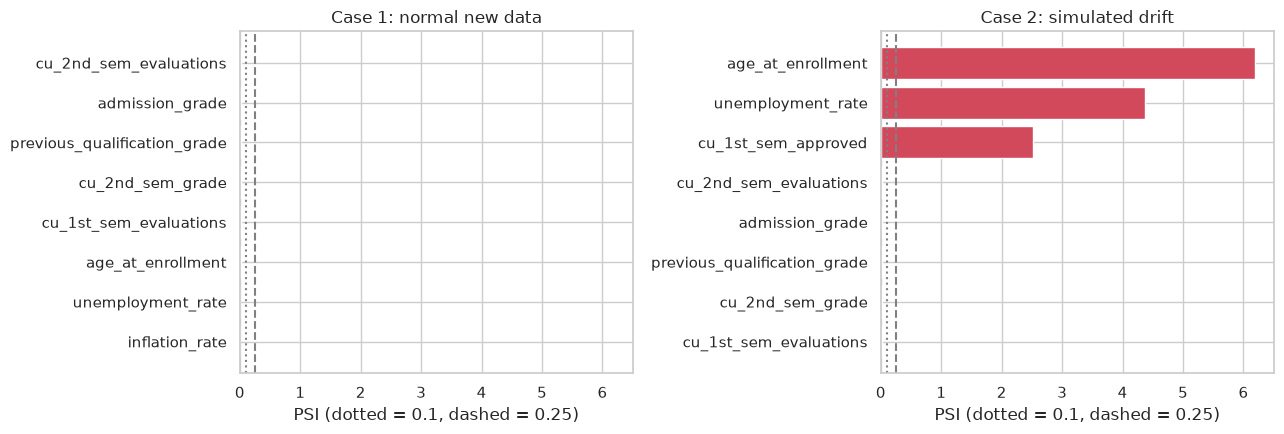

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True)
for ax, rep, title in zip(axes, [rep_ok, rep_bad], ["Case 1: normal new data", "Case 2: simulated drift"]):
    top = rep.head(8)[::-1]
    ax.barh(top.feature.str.replace("curricular_units_", "cu_"), top.psi,
            color=["#d1495b" if p >= 0.25 else "#edae49" if p >= 0.1 else "#00798c" for p in top.psi])
    ax.axvline(0.1, color="grey", ls=":"); ax.axvline(0.25, color="grey", ls="--")
    ax.set_title(title); ax.set_xlabel("PSI (dotted = 0.1, dashed = 0.25)")
save("20_drift_monitoring_demo")
plt.show()

**Result:** the normal data stays in the "stable" range, while the simulated changes are flagged immediately - so the same check, run in the app on logged predictions, would warn us in real life.

---
# Summary of Notebook 3
* **Final test** (unseen data) of both models, with confidence intervals and a comparison with validation.
* **Deployment bundle** (`models/deploy_bundle.joblib`) retrained on train + validation, plus `app_assets.json` and `reference_sample.csv`.
* **Streamlit app** (`app.py`) with Predict, Model info and Monitoring tabs, prediction logging, latency tracking and a feedback form.
* **Monitoring & maintenance plan** with a working drift check.

**Next:** process documentation and the PowerPoint presentation.

---
# Glossary (new terms)
* **Generalisation:** how well a model performs on data it has never seen.
* **Bootstrap / confidence interval:** re-sampling the test set many times to see how much a score would vary by chance.
* **Training/serving skew:** the deployed system computing features differently from how training did.
* **Deployment:** making the model available to real users.
* **Latency:** how long one prediction takes.
* **Data drift:** the real-world data slowly changes compared with the training data.
* **PSI (Population Stability Index):** a number measuring how much a feature's distribution has shifted.